Feature Engineering

Tujuan: Memahami cara membuat dan mengubah fitur dari dataset Titanic setelah melakukan EDA.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
titanic = pd.read_csv('data/titanic.csv')
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Memeriksa Kolom yang Dibutuhkan

In [3]:
titanic[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']].head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare
0,0,3,male,22.0,1,0,7.2500
1,1,1,female,38.0,1,0,71.2833
2,1,3,female,26.0,0,0,7.9250
3,1,1,female,35.0,1,0,53.1000
4,0,3,male,35.0,0,0,8.0500


Memeriksa Nilai Kosong

In [4]:
titanic[['Age', 'Embarked', 'Fare']].isnull().sum()

Age         177
Embarked      2
Fare          0
dtype: int64

In [5]:
titanic['Age'] = titanic['Age'].fillna(titanic['Age'].median())
titanic['Embarked'] = titanic['Embarked'].fillna(titanic['Embarked'].mode()[0])

Membuat Fitur Baru: `FamilySize`

Gabungkan `SibSp` dan `Parch`, lalu tambahkan 1 untuk menghitung penumpang itu sendiri. 
Fitur baru ini merangkum ukuran keluarga yang bepergian bersama.

In [6]:
titanic['FamilySize'] = titanic['SibSp'] + titanic['Parch'] + 1
titanic[['SibSp', 'Parch', 'FamilySize']].head(10)

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1
5,0,0,1
6,0,0,1
7,3,1,5
8,0,2,3
9,1,0,2


Membuat Fitur Biner: `IsAlone`

Fitur ini bernilai 1 jika penumpang bepergian sendirian, dan 0 jika tidak.

In [7]:
titanic['IsAlone'] = (titanic['FamilySize'] == 1).astype(int)
titanic[['FamilySize', 'IsAlone']].head(10)

,FamilySize,IsAlone
0,2,0
1,2,0
2,1,1
3,2,0
4,1,1
5,1,1
6,1,1
7,5,0
8,3,0
9,2,0


Mengubah Fitur Kategorikal dengan OneHot Encoding

Kolom `Sex` berisi kategori teks. OneHot encoding mengubah kategori menjadi kolom numerik, misalnya `Sex_male` dan `Sex_female`.

In [8]:
titanic_encoded = pd.get_dummies(
    titanic,
    columns=['Sex', 'Embarked'],
    dtype=int
)
titanic_encoded[['Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']].head()

,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,1,0,0,1
1,1,0,1,0,0
2,1,0,0,0,1
3,1,0,0,0,1
4,0,1,0,0,1


Membuat Kelompok Usia

In [9]:
titanic['AgeGroup'] = pd.cut(
    titanic['Age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Child', 'Teen', 'Young Adult', 'Adult', 'Senior'],
    include_lowest=True
)
titanic[['Age', 'AgeGroup']].head(10)

,Age,AgeGroup
0,22.0,Young Adult
1,38.0,Adult
2,26.0,Young Adult
3,35.0,Young Adult
4,35.0,Young Adult
5,28.0,Young Adult
6,54.0,Adult
7,2.0,Child
8,27.0,Young Adult
9,14.0,Teen


Melihat Hubungan Fitur Baru dengan Keselamatan

`Survived` adalah label yang menunjukkan apakah penumpang selamat (1) atau tidak (0). Membandingkan rata-rata keselamatan berdasarkan ukuran keluarga.

In [10]:
titanic.groupby('FamilySize', observed=True)['Survived'].mean().round(3)

FamilySize
1     0.304
2     0.553
3     0.578
4     0.724
5     0.200
6     0.136
7     0.333
8     0.000
11    0.000
Name: Survived, dtype: float64

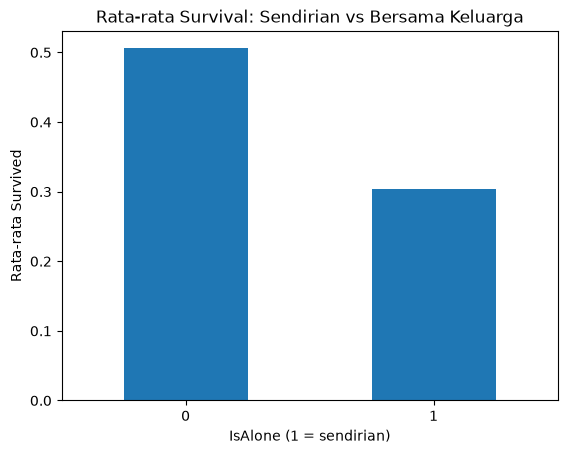

In [11]:
titanic.groupby('IsAlone', observed=True)['Survived'].mean().plot(kind='bar')
plt.title('Rata-rata Survival: Sendirian vs Bersama Keluarga')
plt.xlabel('IsAlone (1 = sendirian)')
plt.ylabel('Rata-rata Survived')
plt.xticks(rotation=0)
plt.show()

Menyimpan Hasil

Simpan dataset yang sudah memiliki fitur baru.

In [12]:
titanic.to_csv('titanic_feature_engineered.csv', index=False)
print('File tersimpan: titanic_feature_engineered.csv')

File tersimpan: titanic_feature_engineered.csv
